In [1]:
#%pip install ultralytics opencv-python matplotlib 

In [2]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

In [3]:
model = YOLO("yolo11n.pt")

In [4]:
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.5,
    save=True
)

results[0].show()


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 c:\Users\DELL\OneDrive\Desktop\HomeCareIOT\routine_notebooks\bus.jpg: 640x480 4 persons, 1 bus, 202.6ms
Speed: 12.8ms preprocess, 202.6ms inference, 17.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\routine_notebooks\runs\detect\predict-4


In [5]:
from pathlib import Path

PROJECT_DIR = Path.home() / "OneDrive" / "Desktop" / "HomeCareIOT"

VIDEO_DIR = (
    PROJECT_DIR
    / "toyota_datasets"
    / "trimmed"
    / "toyota_smarthome_mp4"
    / "mp4"
)

print("Dataset folder exists:", VIDEO_DIR.exists())

Dataset folder exists: True


In [6]:
video_files = sorted(
    path for path in VIDEO_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in {".mp4", ".avi", ".mov", ".mkv"}
)

print("Total videos found:", len(video_files))

for video in video_files[:5]:
    print(video.name)

Total videos found: 16115
Cook.Cleandishes_p02_r00_v02_c03.mp4
Cook.Cleandishes_p02_r00_v14_c03.mp4
Cook.Cleandishes_p02_r00_v16_c06.mp4
Cook.Cleandishes_p02_r01_v02_c03.mp4
Cook.Cleandishes_p03_r00_v15_c03.mp4


In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

video_files = sorted(
    path for path in VIDEO_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in {".mp4", ".avi", ".mov", ".mkv"}
)

print("Total video files:", len(video_files))

print("\nFirst 10 filenames:")
for video in video_files[:10]:
    print(video.name)

Total video files: 16115

First 10 filenames:
Cook.Cleandishes_p02_r00_v02_c03.mp4
Cook.Cleandishes_p02_r00_v14_c03.mp4
Cook.Cleandishes_p02_r00_v16_c06.mp4
Cook.Cleandishes_p02_r01_v02_c03.mp4
Cook.Cleandishes_p03_r00_v15_c03.mp4
Cook.Cleandishes_p03_r00_v15_c06.mp4
Cook.Cleandishes_p03_r00_v16_c03.mp4
Cook.Cleandishes_p03_r00_v16_c06.mp4
Cook.Cleandishes_p03_r00_v18_c03.mp4
Cook.Cleandishes_p03_r00_v18_c06.mp4


In [8]:
import re

records = []

for video in video_files:
    match = re.match(r"(.+?)_p\d+_", video.stem)

    if match:
        activity = match.group(1)
    else:
        activity = "UNKNOWN"

    records.append({
        "video_name": video.name,
        "activity": activity,
        "video_path": str(video)
    })

df = pd.DataFrame(records)

print("Total videos:", len(df))
print("Videos with identifiable activity:", (df["activity"] != "UNKNOWN").sum())
print("Videos with unknown activity:", (df["activity"] == "UNKNOWN").sum())

Total videos: 16115
Videos with identifiable activity: 16115
Videos with unknown activity: 0


In [9]:
activity_counts = (
    df[df["activity"] != "UNKNOWN"]["activity"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Number of activity classes:", len(activity_counts))
print("\nVideos per activity:")
print(activity_counts.to_string())

Number of activity classes: 31

Videos per activity:
activity
Walk                     4070
Drink.Fromcup            2241
Sitdown                  1116
Readbook                  942
Getup                     833
WatchTV                   712
Eat.Attable               617
Cook.Stir                 579
Usetelephone              451
Enter                     444
Leave                     416
Uselaptop                 396
Cook.Cleanup              380
Cook.Cleandishes          378
Takepills                 344
Drink.Frombottle          341
Drink.Fromcan             325
Pour.Frombottle           276
Eat.Snack                 216
Laydown                   181
Cook.Cut                  178
Pour.Fromkettle           107
Cook.Usestove              96
Makecoffee.Pourwater       76
Drink.Fromglass            65
Makecoffee.Pourgrains      64
Maketea.Boilwater          62
Pour.Fromcan               59
Maketea.Insertteabag       56
Usetablet                  49
Cutbread                   45


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

activity_counts = (
    df[df["activity"] != "UNKNOWN"]["activity"]
    .value_counts()
    .sort_values(ascending=False)
)

distribution = pd.DataFrame({
    "Activity": activity_counts.index,
    "Video_Count": activity_counts.values
})

distribution["Percentage"] = (
    distribution["Video_Count"]
    / distribution["Video_Count"].sum()
    * 100
)

print(distribution.to_string(index=False))

print("\nTotal videos:", distribution["Video_Count"].sum())
print("Number of classes:", len(distribution))

print("\nLargest class:", distribution.iloc[0]["Activity"])
print("Largest class count:", distribution.iloc[0]["Video_Count"])

print("\nSmallest class:", distribution.iloc[-1]["Activity"])
print("Smallest class count:", distribution.iloc[-1]["Video_Count"])

print(
    "\nImbalance ratio:",
    round(
        distribution["Video_Count"].max()
        / distribution["Video_Count"].min(),
        2
    )
)

             Activity  Video_Count  Percentage
                 Walk         4070   25.255973
        Drink.Fromcup         2241   13.906298
              Sitdown         1116    6.925225
             Readbook          942    5.845486
                Getup          833    5.169097
              WatchTV          712    4.418244
          Eat.Attable          617    3.828731
            Cook.Stir          579    3.592926
         Usetelephone          451    2.798635
                Enter          444    2.755197
                Leave          416    2.581446
            Uselaptop          396    2.457338
         Cook.Cleanup          380    2.358052
     Cook.Cleandishes          378    2.345641
            Takepills          344    2.134657
     Drink.Frombottle          341    2.116041
        Drink.Fromcan          325    2.016755
      Pour.Frombottle          276    1.712690
            Eat.Snack          216    1.340366
              Laydown          181    1.123177
             

In [11]:
import pandas as pd

metadata = df[["video_name", "activity", "video_path"]].copy()

metadata.to_csv(
    PROJECT_DIR / "toyota_activity_metadata.csv",
    index=False
)

print("Metadata saved successfully!")
print("Total videos:", len(metadata))
print("Total activities:", metadata["activity"].nunique())

Metadata saved successfully!
Total videos: 16115
Total activities: 31


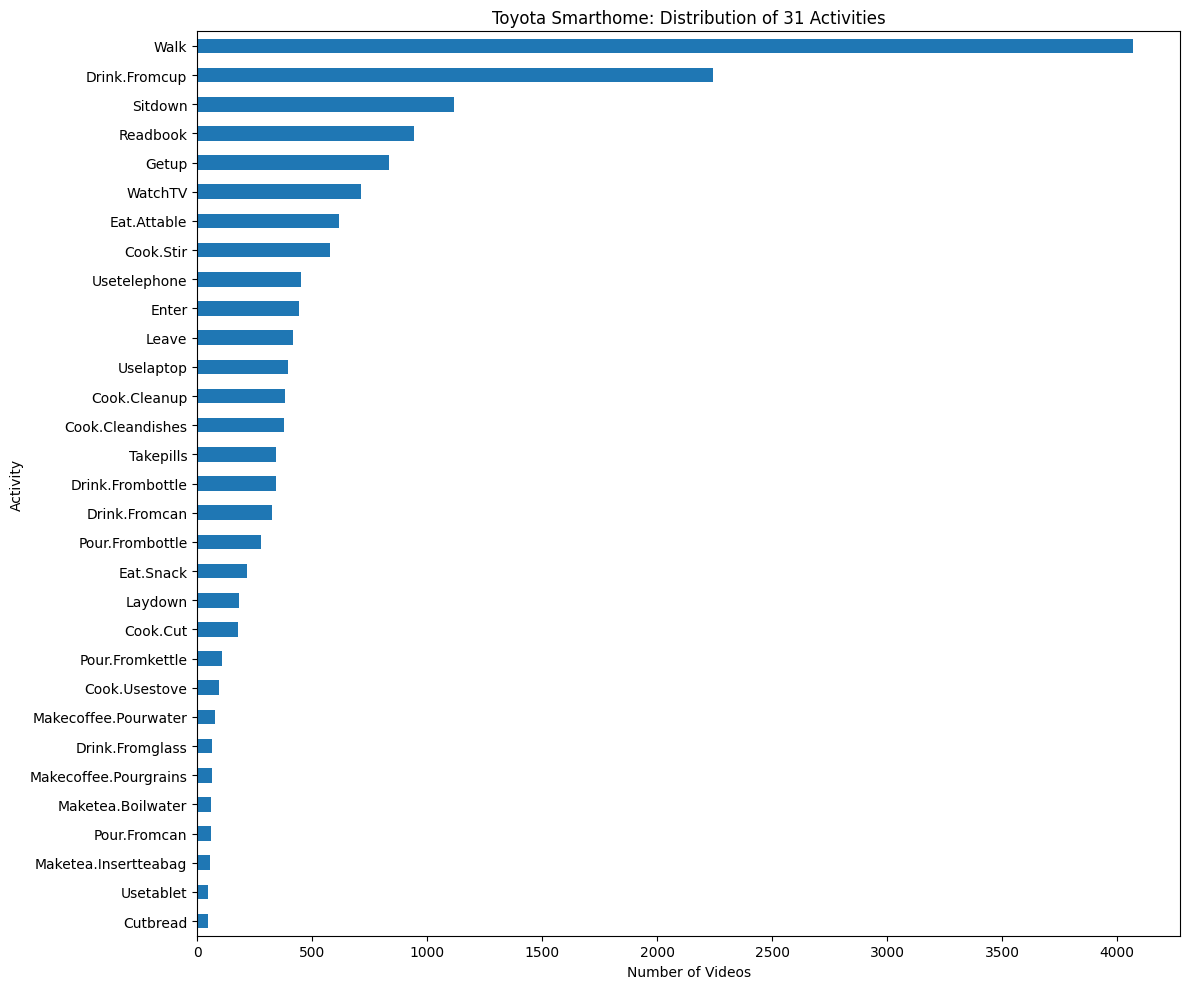

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

activity_counts.sort_values().plot(kind="barh")

plt.title("Toyota Smarthome: Distribution of 31 Activities")
plt.xlabel("Number of Videos")
plt.ylabel("Activity")

plt.tight_layout()
plt.show()

In [13]:
print("Duplicate filenames:", df["video_name"].duplicated().sum())
print("Duplicate video paths:", df["video_path"].duplicated().sum())
print("Missing activity labels:", (df["activity"] == "UNKNOWN").sum())

Duplicate filenames: 0
Duplicate video paths: 0
Missing activity labels: 0


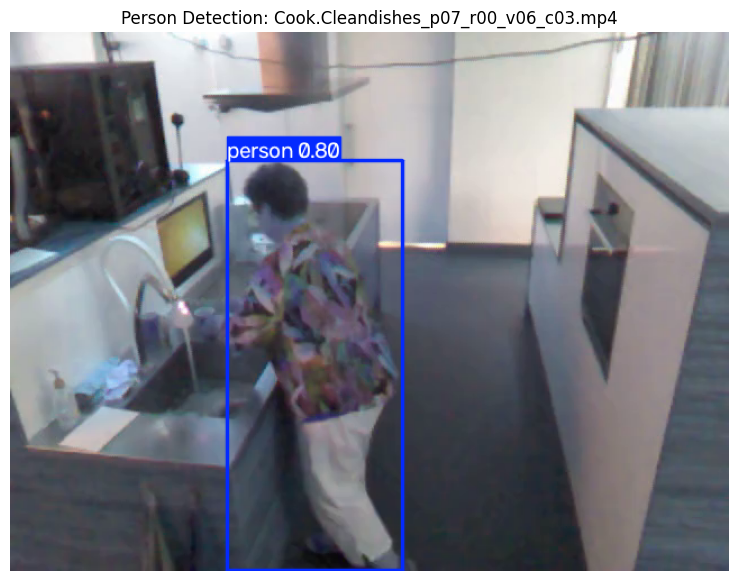

People detected: 1


In [57]:
import cv2
import matplotlib.pyplot as plt

video_path = video_files[99]

cap = cv2.VideoCapture(str(video_path))

success, frame = cap.read()

cap.release()

if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    results = model.predict(
        source=frame_rgb,
        classes=[0],
        conf=0.5,
        verbose=False
    )

    annotated_frame = cv2.cvtColor(
        results[0].plot(),
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 7))
    plt.imshow(annotated_frame)
    plt.title(f"Person Detection: {video_path.name}")
    plt.axis("off")
    plt.show()

    print("People detected:", len(results[0].boxes))
else:
    print("Could not read the video.")

Total frames: 153
FPS: 20.0


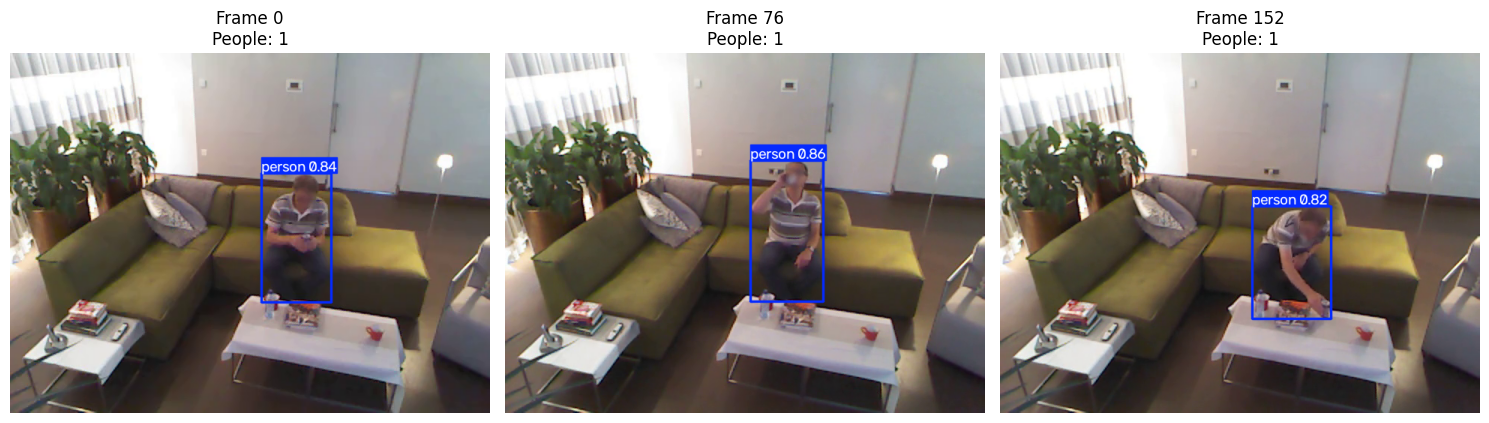

In [15]:

import cv2
import matplotlib.pyplot as plt

video_path = str(video_files[2199]) #law aayza video tany haghyar el rakam el gwa el pracket

cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)

print("Total frames:", total_frames)
print("FPS:", fps)

frames_to_check = [0, total_frames // 2, total_frames - 1]
detected_frames = []

for frame_number in frames_to_check:
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    success, frame = cap.read()

    if success:
        results = model.predict(
            source=frame,
            classes=[0],
            conf=0.5,
            verbose=False
        )

        annotated_frame = results[0].plot()
        annotated_frame = cv2.cvtColor(
            annotated_frame, cv2.COLOR_BGR2RGB
        )

        detected_frames.append(
            (frame_number, annotated_frame, len(results[0].boxes))
        )

cap.release()

fig, axes = plt.subplots(1, len(detected_frames), figsize=(15, 5))

if len(detected_frames) == 1:
    axes = [axes]

for ax, (frame_number, image, people_count) in zip(axes, detected_frames):
    ax.imshow(image)
    ax.set_title(f"Frame {frame_number}\nPeople: {people_count}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#video duration=total_frames / fps

In [16]:
from ultralytics import YOLO

pose_model = YOLO("yolo11n-pose.pt")
print("YOLO Pose model loaded successfully!")


YOLO Pose model loaded successfully!


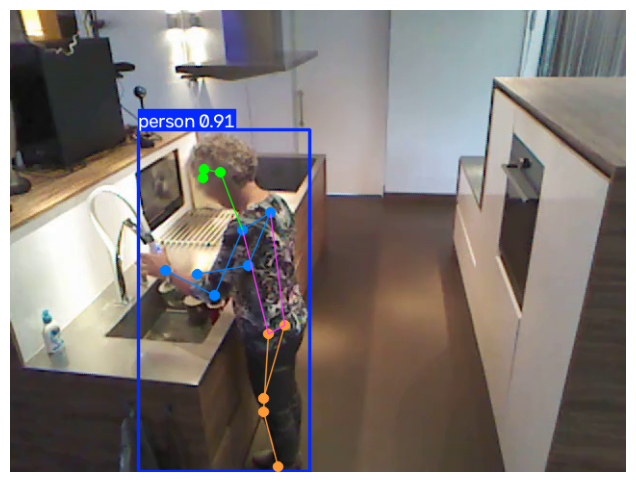

Keypoints shape: torch.Size([1, 17, 3])
Number of people detected: 1


In [17]:

import cv2
import matplotlib.pyplot as plt

video_path = str(video_files[0])

cap = cv2.VideoCapture(video_path)
success, frame = cap.read()
cap.release()

if success:
    results = pose_model.predict(
        source=frame,
        conf=0.5,
        verbose=False
    )

    annotated_frame = results[0].plot()
    annotated_frame = cv2.cvtColor(
        annotated_frame, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(10, 6))
    plt.imshow(annotated_frame)
    plt.axis("off")
    plt.show()

    if results[0].keypoints is not None:
        print("Keypoints shape:", results[0].keypoints.data.shape)
        print("Number of people detected:", len(results[0].keypoints))
else:
    print("Could not read the video.")

In [18]:

import cv2
import numpy as np

video_path = str(video_files[0])

cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

number_of_samples = min(20, total_frames)

frame_indices = np.linspace(
    0,
    total_frames - 1,
    number_of_samples,
    dtype=int
)

all_keypoints = []

for frame_number in frame_indices:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_number))
    success, frame = cap.read()

    if not success:
        continue

    results = pose_model.predict(
        source=frame,
        conf=0.5,
        verbose=False
    )

    if results[0].keypoints is not None and len(results[0].keypoints) > 0:
        keypoints = results[0].keypoints.data[0].cpu().numpy()
    else:
        keypoints = np.zeros((17, 3), dtype=np.float32)

    all_keypoints.append(keypoints)

cap.release()

all_keypoints = np.array(all_keypoints)

print("Keypoints array shape:", all_keypoints.shape)
print("Frames processed:", len(all_keypoints))


Keypoints array shape: (20, 17, 3)
Frames processed: 20


In [19]:
output_dir = PROJECT_DIR / "pose_features"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / f"{video_files[0].stem}_keypoints.npy"

np.save(output_path, all_keypoints)

print("Saved to:", output_path)
print("File exists:", output_path.exists())


Saved to: C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\pose_features\Cook.Cleandishes_p02_r00_v02_c03_keypoints.npy
File exists: True


In [20]:

import json
from pathlib import Path

SKELETON_DIR = (
    PROJECT_DIR
    / "toyota_datasets"
    / "trimmed"
    / "toyota_smarthome_skeleton"
    / "json"
)

json_files = sorted(SKELETON_DIR.glob("*.json"))

print("Total JSON files:", len(json_files))
print("First JSON file:", json_files[0].name)

with open(json_files[0], "r") as file:
    skeleton_data = json.load(file)

print("\nData type:", type(skeleton_data))
print("\nFirst part of the data:")
print(str(skeleton_data)[:2000])


Total JSON files: 16115
First JSON file: Cook.Cleandishes_p02_r00_v02_c03.json

Data type: <class 'dict'>

First part of the data:
{'K': 20, 'njts': 13, 'frames': [[{'cumscore': 8.43447494506836, 'pose2d': [264.350341796875, 292.28857421875, 258.7521667480469, 272.3367919921875, 279.0132141113281, 269.8716735839844, 230.6715850830078, 188.52236938476562, 269.09417724609375, 221.47463989257812, 272.2390441894531, 242.98703002929688, 223.62570190429688, 454.2058410644531, 476.3174133300781, 386.562744140625, 406.874267578125, 315.3120422363281, 328.2059631347656, 260.31512451171875, 283.9359130859375, 244.87631225585938, 290.034423828125, 199.89932250976562, 232.9442138671875, 174.37896728515625], 'pose3d': [-0.013501551933586597, -0.14018067717552185, 0.03889404982328415, -0.01468866690993309, -0.052195221185684204, -0.019107796251773834, 0.1497691571712494, 0.3384685516357422, -0.01354127749800682, 0.20444869995117188, -0.01537160761654377, 0.10283246636390686, 0.16161373257637024, -0.

In [21]:
print("JSON keys:", skeleton_data.keys())

frames = skeleton_data["frames"]

print("Number of frames:", len(frames))
print("Number of people in first frame:", len(frames[0]))

person = frames[0][0]

print("Person data keys:", person.keys())
print("Number of 2D pose values:", len(person["pose2d"]))
print("Number of 3D pose values:", len(person["pose3d"]))

print("\n2D pose values:")
print(person["pose2d"])

print("\n3D pose values:")
print(person["pose3d"])


JSON keys: dict_keys(['K', 'njts', 'frames'])
Number of frames: 101
Number of people in first frame: 1
Person data keys: dict_keys(['cumscore', 'pose2d', 'pose3d'])
Number of 2D pose values: 26
Number of 3D pose values: 39

2D pose values:
[264.350341796875, 292.28857421875, 258.7521667480469, 272.3367919921875, 279.0132141113281, 269.8716735839844, 230.6715850830078, 188.52236938476562, 269.09417724609375, 221.47463989257812, 272.2390441894531, 242.98703002929688, 223.62570190429688, 454.2058410644531, 476.3174133300781, 386.562744140625, 406.874267578125, 315.3120422363281, 328.2059631347656, 260.31512451171875, 283.9359130859375, 244.87631225585938, 290.034423828125, 199.89932250976562, 232.9442138671875, 174.37896728515625]

3D pose values:
[-0.013501551933586597, -0.14018067717552185, 0.03889404982328415, -0.01468866690993309, -0.052195221185684204, -0.019107796251773834, 0.1497691571712494, 0.3384685516357422, -0.01354127749800682, 0.20444869995117188, -0.01537160761654377, 0.102

In [22]:

import json
from collections import Counter

total_files = 0
valid_files = 0
empty_files = 0
error_files = []
frame_counts = []
joint_counts = Counter()

for json_path in json_files:
    total_files += 1

    try:
        with open(json_path, "r") as file:
            data = json.load(file)

        frames = data.get("frames", [])

        if not frames:
            empty_files += 1
            continue

        person = next(
            (person for frame in frames for person in frame),
            None
        )

        if person is None:
            empty_files += 1
            continue

        if (
            len(person.get("pose2d", [])) == 26
            and len(person.get("pose3d", [])) == 39
        ):
            valid_files += 1
            frame_counts.append(len(frames))
            joint_counts[data.get("njts")] += 1
        else:
            error_files.append(json_path.name)

    except Exception:
        error_files.append(json_path.name)

print("Total files checked:", total_files)
print("Files with expected pose data:", valid_files)
print("Empty files:", empty_files)
print("Files with errors or unexpected pose lengths:", len(error_files))
print("Joint-count distribution:", joint_counts)
if frame_counts:
    print("Shortest video (frames):", min(frame_counts))
    print("Longest video (frames):", max(frame_counts))



Total files checked: 16115
Files with expected pose data: 15871
Empty files: 244
Files with errors or unexpected pose lengths: 0
Joint-count distribution: Counter({13: 15871})
Shortest video (frames): 31
Longest video (frames): 3493


In [23]:

import re
import pandas as pd

def get_activity(filename):
    match = re.match(r"(.+?)_p\d+_", filename)
    return match.group(1) if match else "UNKNOWN"

skeleton_records = []

for path in json_files:
    skeleton_records.append({
        "video_name": path.stem + ".mp4",
        "activity": get_activity(path.stem),
        "json_path": str(path)
    })

skeleton_df = pd.DataFrame(skeleton_records)

video_names = {path.name for path in video_files}

skeleton_df["video_exists"] = skeleton_df["video_name"].isin(
    video_names
)

print("Total skeleton files:", len(skeleton_df))
print("Recognized activity labels:",
      skeleton_df["activity"].nunique())
print("Unknown labels:",
      (skeleton_df["activity"] == "UNKNOWN").sum())
print("Matching MP4 files:",
      skeleton_df["video_exists"].sum())
print("Missing matching MP4 files:",
      (~skeleton_df["video_exists"]).sum())

print("\nActivity counts:")
print(skeleton_df["activity"].value_counts())


Total skeleton files: 16115
Recognized activity labels: 31
Unknown labels: 0
Matching MP4 files: 16115
Missing matching MP4 files: 0

Activity counts:
activity
Walk                     4070
Drink.Fromcup            2241
Sitdown                  1116
Readbook                  942
Getup                     833
WatchTV                   712
Eat.Attable               617
Cook.Stir                 579
Usetelephone              451
Enter                     444
Leave                     416
Uselaptop                 396
Cook.Cleanup              380
Cook.Cleandishes          378
Takepills                 344
Drink.Frombottle          341
Drink.Fromcan             325
Pour.Frombottle           276
Eat.Snack                 216
Laydown                   181
Cook.Cut                  178
Pour.Fromkettle           107
Cook.Usestove              96
Makecoffee.Pourwater       76
Drink.Fromglass            65
Makecoffee.Pourgrains      64
Maketea.Boilwater          62
Pour.Fromcan               59


In [24]:

import json
import pandas as pd

valid_records = []

for _, row in skeleton_df.iterrows():
    if row["activity"] == "UNKNOWN":
        continue

    json_path = Path(row["json_path"])

    try:
        with open(json_path, "r") as file:
            data = json.load(file)

        frames = data.get("frames", [])

        has_valid_pose = any(
            len(person.get("pose2d", [])) == 26
            and len(person.get("pose3d", [])) == 39
            for frame in frames
            for person in frame
        )

        if has_valid_pose:
            valid_records.append({
                "video_name": row["video_name"],
                "activity": row["activity"],
                "json_path": str(json_path),
                "num_frames": len(frames)
            })

    except (json.JSONDecodeError, OSError):
        continue

clean_df = pd.DataFrame(valid_records)

output_csv = PROJECT_DIR / "toyota_clean_metadata.csv"
clean_df.to_csv(output_csv, index=False)

print("Usable videos:", len(clean_df))
print("Activity classes:", clean_df["activity"].nunique())
print("Saved metadata:", output_csv)
print("\nFirst five rows:")
print(clean_df.head())



Usable videos: 15871
Activity classes: 31
Saved metadata: C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\toyota_clean_metadata.csv

First five rows:
                             video_name          activity  \
0  Cook.Cleandishes_p02_r00_v02_c03.mp4  Cook.Cleandishes   
1  Cook.Cleandishes_p02_r00_v14_c03.mp4  Cook.Cleandishes   
2  Cook.Cleandishes_p02_r00_v16_c06.mp4  Cook.Cleandishes   
3  Cook.Cleandishes_p02_r01_v02_c03.mp4  Cook.Cleandishes   
4  Cook.Cleandishes_p03_r00_v15_c03.mp4  Cook.Cleandishes   

                                           json_path  num_frames  
0  C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\toy...         101  
1  C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\toy...         115  
2  C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\toy...        1665  
3  C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\toy...          97  
4  C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\toy...         715  


In [25]:

import json
import numpy as np

sample_row = clean_df.iloc[0]

with open(sample_row["json_path"], "r") as file:
    sample_data = json.load(file)

pose_sequence = []

for frame in sample_data["frames"]:
    if frame and len(frame[0].get("pose3d", [])) == 39:
        pose = np.array(
            frame[0]["pose3d"],
            dtype=np.float32
        ).reshape(13, 3)
    else:
        pose = np.zeros((13, 3), dtype=np.float32)

    pose_sequence.append(pose)

pose_sequence = np.array(pose_sequence)

print("Activity:", sample_row["activity"])
print("Sequence shape:", pose_sequence.shape)
print("Number of frames:", len(pose_sequence))
print("Joints per frame:", pose_sequence.shape[1])
print("Coordinates per joint:", pose_sequence.shape[2])



Activity: Cook.Cleandishes
Sequence shape: (101, 13, 3)
Number of frames: 101
Joints per frame: 13
Coordinates per joint: 3


In [26]:

import numpy as np

SEQUENCE_LENGTH = 30

def prepare_sequence(json_path, sequence_length=SEQUENCE_LENGTH):
    with open(json_path, "r") as file:
        data = json.load(file)

    frames = data["frames"]
    sequence = []

    for frame in frames:
        if frame and len(frame[0].get("pose3d", [])) == 39:
            pose = np.array(
                frame[0]["pose3d"],
                dtype=np.float32
            ).reshape(13, 3)
        else:
            pose = np.zeros((13, 3), dtype=np.float32)

        sequence.append(pose)

    sequence = np.array(sequence, dtype=np.float32)

    indices = np.linspace(
        0, len(sequence) - 1, sequence_length, dtype=int
    )

    return sequence[indices]

sample_sequence = prepare_sequence(clean_df.iloc[0]["json_path"])

print("Activity:", clean_df.iloc[0]["activity"])
print("Prepared shape:", sample_sequence.shape)
print("All values finite:", np.isfinite(sample_sequence).all())


Activity: Cook.Cleandishes
Prepared shape: (30, 13, 3)
All values finite: True


In [27]:

import numpy as np
from pathlib import Path

FEATURE_DIR = PROJECT_DIR / "processed_skeletons"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

labels = sorted(clean_df["activity"].unique())
label_to_id = {label: i for i, label in enumerate(labels)}

X = np.zeros(
    (len(clean_df), SEQUENCE_LENGTH, 13, 3),
    dtype=np.float32
)

y = np.zeros(len(clean_df), dtype=np.int32)

for i, (_, row) in enumerate(clean_df.iterrows()):
    X[i] = prepare_sequence(row["json_path"])
    y[i] = label_to_id[row["activity"]]

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(clean_df)} videos")

np.save(FEATURE_DIR / "X.npy", X)
np.save(FEATURE_DIR / "y.npy", y)
np.save(FEATURE_DIR / "labels.npy", np.array(labels))

print("\nProcessing complete!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", len(labels))
print("Saved to:", FEATURE_DIR)


Processed 500/15871 videos
Processed 1000/15871 videos
Processed 1500/15871 videos
Processed 2000/15871 videos
Processed 2500/15871 videos
Processed 3000/15871 videos
Processed 3500/15871 videos
Processed 4000/15871 videos
Processed 4500/15871 videos
Processed 5000/15871 videos
Processed 5500/15871 videos
Processed 6000/15871 videos
Processed 6500/15871 videos
Processed 7000/15871 videos
Processed 7500/15871 videos
Processed 8000/15871 videos
Processed 8500/15871 videos
Processed 9000/15871 videos
Processed 9500/15871 videos
Processed 10000/15871 videos
Processed 10500/15871 videos
Processed 11000/15871 videos
Processed 11500/15871 videos
Processed 12000/15871 videos
Processed 12500/15871 videos
Processed 13000/15871 videos
Processed 13500/15871 videos
Processed 14000/15871 videos
Processed 14500/15871 videos
Processed 15000/15871 videos
Processed 15500/15871 videos

Processing complete!
X shape: (15871, 30, 13, 3)
y shape: (15871,)
Number of classes: 31
Saved to: C:\Users\DELL\OneDriv

In [28]:

import numpy as np

FEATURE_DIR = PROJECT_DIR / "processed_skeletons"

X_check = np.load(FEATURE_DIR / "X.npy", mmap_mode="r")
y_check = np.load(FEATURE_DIR / "y.npy")
labels_check = np.load(FEATURE_DIR / "labels.npy")

print("X shape:", X_check.shape)
print("y shape:", y_check.shape)
print("Labels:", len(labels_check))
print("All X values finite:", np.isfinite(X_check).all())
print("All labels valid:", y_check.min() >= 0 and y_check.max() < len(labels_check))
print("Saved files verified!")


X shape: (15871, 30, 13, 3)
y shape: (15871,)
Labels: 31
All X values finite: True
All labels valid: True
Saved files verified!


In [29]:

SEQUENCE_LENGTH_60 = 60

FEATURE_DIR = PROJECT_DIR / "processed_skeletons"

X_60 = np.zeros((len(clean_df), SEQUENCE_LENGTH_60, 13, 3), dtype=np.float32)

for i, (_, row) in enumerate(clean_df.iterrows()):
    X_60[i] = prepare_sequence(
        row["json_path"],
        sequence_length=SEQUENCE_LENGTH_60
    )

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(clean_df)} videos")

np.save(FEATURE_DIR / "X_60.npy", X_60)

print("X_60 shape:", X_60.shape)
print("Saved:", FEATURE_DIR / "X_60.npy")


Processed 500/15871 videos
Processed 1000/15871 videos
Processed 1500/15871 videos
Processed 2000/15871 videos
Processed 2500/15871 videos
Processed 3000/15871 videos
Processed 3500/15871 videos
Processed 4000/15871 videos
Processed 4500/15871 videos
Processed 5000/15871 videos
Processed 5500/15871 videos
Processed 6000/15871 videos
Processed 6500/15871 videos
Processed 7000/15871 videos
Processed 7500/15871 videos
Processed 8000/15871 videos
Processed 8500/15871 videos
Processed 9000/15871 videos
Processed 9500/15871 videos
Processed 10000/15871 videos
Processed 10500/15871 videos
Processed 11000/15871 videos
Processed 11500/15871 videos
Processed 12000/15871 videos
Processed 12500/15871 videos
Processed 13000/15871 videos
Processed 13500/15871 videos
Processed 14000/15871 videos
Processed 14500/15871 videos
Processed 15000/15871 videos
Processed 15500/15871 videos
X_60 shape: (15871, 60, 13, 3)
Saved: C:\Users\DELL\OneDrive\Desktop\HomeCareIOT\processed_skeletons\X_60.npy


In [30]:

from sklearn.model_selection import train_test_split
import numpy as np

FEATURE_DIR = PROJECT_DIR / "processed_skeletons"

X = np.load(FEATURE_DIR / "X_60.npy")
y = np.load(FEATURE_DIR / "y.npy")
labels = np.load(FEATURE_DIR / "labels.npy")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)
print("Number of classes:", len(labels))


Training data: (12696, 60, 13, 3)
Testing data: (3175, 60, 13, 3)
Training labels: (12696,)
Testing labels: (3175,)
Number of classes: 31


In [31]:

print(clean_df["video_name"].head(10).to_string(index=False))


Cook.Cleandishes_p02_r00_v02_c03.mp4
Cook.Cleandishes_p02_r00_v14_c03.mp4
Cook.Cleandishes_p02_r00_v16_c06.mp4
Cook.Cleandishes_p02_r01_v02_c03.mp4
Cook.Cleandishes_p03_r00_v15_c03.mp4
Cook.Cleandishes_p03_r00_v15_c06.mp4
Cook.Cleandishes_p03_r00_v16_c03.mp4
Cook.Cleandishes_p03_r00_v16_c06.mp4
Cook.Cleandishes_p03_r00_v18_c03.mp4
Cook.Cleandishes_p03_r00_v18_c06.mp4


In [32]:

import re

def extract_metadata(filename):
    match = re.search(r"_p(\d+)_r(\d+)_v(\d+)_c(\d+)", filename)

    if match:
        return match.groups()

    return None

for filename in clean_df["video_name"].head(10):
    print(filename, "->", extract_metadata(filename))



Cook.Cleandishes_p02_r00_v02_c03.mp4 -> ('02', '00', '02', '03')
Cook.Cleandishes_p02_r00_v14_c03.mp4 -> ('02', '00', '14', '03')
Cook.Cleandishes_p02_r00_v16_c06.mp4 -> ('02', '00', '16', '06')
Cook.Cleandishes_p02_r01_v02_c03.mp4 -> ('02', '01', '02', '03')
Cook.Cleandishes_p03_r00_v15_c03.mp4 -> ('03', '00', '15', '03')
Cook.Cleandishes_p03_r00_v15_c06.mp4 -> ('03', '00', '15', '06')
Cook.Cleandishes_p03_r00_v16_c03.mp4 -> ('03', '00', '16', '03')
Cook.Cleandishes_p03_r00_v16_c06.mp4 -> ('03', '00', '16', '06')
Cook.Cleandishes_p03_r00_v18_c03.mp4 -> ('03', '00', '18', '03')
Cook.Cleandishes_p03_r00_v18_c06.mp4 -> ('03', '00', '18', '06')


In [33]:

metadata = clean_df["video_name"].str.extract(
    r"_p(\d+)_r(\d+)_v(\d+)_c(\d+)"
)

metadata.columns = ["p", "r", "v", "c"]

for column in metadata.columns:
    print(f"\n{column}: {metadata[column].nunique()} unique values")
    print(sorted(metadata[column].unique()))



p: 18 unique values
['02', '03', '04', '06', '07', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '25']

r: 54 unique values
['00', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53']

v: 27 unique values
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27']

c: 7 unique values
['01', '02', '03', '04', '05', '06', '07']


In [34]:

train_subjects = {
    "03", "04", "06", "07", "09", "12",
    "13", "15", "17", "19", "25"
}

test_subjects = set(metadata["p"].unique()) - train_subjects

print("Training subjects:", sorted(train_subjects))
print("Testing subjects:", sorted(test_subjects))
print("Training subject count:", len(train_subjects))
print("Testing subject count:", len(test_subjects))


Training subjects: ['03', '04', '06', '07', '09', '12', '13', '15', '17', '19', '25']
Testing subjects: ['02', '10', '11', '14', '16', '18', '20']
Training subject count: 11
Testing subject count: 7


In [35]:

train_subjects = {
    "03", "04", "06", "07", "09", "12",
    "13", "15", "17", "19", "25"
}

metadata = clean_df["video_name"].str.extract(
    r"_p(\d+)_r(\d+)_v(\d+)_c(\d+)"
)
metadata.columns = ["p", "r", "v", "c"]

train_mask = metadata["p"].isin(train_subjects).to_numpy()
test_mask = ~train_mask

X_60 = np.load(FEATURE_DIR / "X_60.npy", mmap_mode="r")
y = np.load(FEATURE_DIR / "y.npy")

X_train = X_60[train_mask]
y_train = y[train_mask]

X_test = X_60[test_mask]
y_test = y[test_mask]

print("Training videos:", len(y_train))
print("Testing videos:", len(y_test))
print("Training classes:", len(np.unique(y_train)))
print("Testing classes:", len(np.unique(y_test)))
print("Subject overlap:", set(metadata.loc[train_mask, "p"]) &
      set(metadata.loc[test_mask, "p"]))


Training videos: 10517
Testing videos: 5354
Training classes: 31
Testing classes: 31
Subject overlap: set()


In [36]:

print("Minimum coordinate:", X_train.min())
print("Maximum coordinate:", X_train.max())
print("Mean coordinate:", X_train.mean())
print("Standard deviation:", X_train.std())

print("Training data shape:", X_train.shape)


Minimum coordinate: -1.1398803
Maximum coordinate: 1.1359589
Mean coordinate: -0.047726434
Standard deviation: 0.2758949
Training data shape: (10517, 60, 13, 3)


In [37]:

zero_frames = np.all(X_train == 0, axis=(2, 3))

print("Total training frames:", zero_frames.size)
print("Completely zero frames:", zero_frames.sum())
print("Percentage of zero frames:", round(zero_frames.mean() * 100, 2), "%")


Total training frames: 631020
Completely zero frames: 52117
Percentage of zero frames: 8.26 %


In [38]:

zero_frames_per_video = zero_frames.sum(axis=1)
missing_percent = zero_frames_per_video / X_train.shape[1] * 100

print("Videos with at least one zero frame:",
      (zero_frames_per_video > 0).sum())

print("Videos with more than 25% zero frames:",
      (missing_percent > 25).sum())

print("Videos with more than 50% zero frames:",
      (missing_percent > 50).sum())

print("Videos with 100% zero frames:",
      (missing_percent == 100).sum())


Videos with at least one zero frame: 3243
Videos with more than 25% zero frames: 1251
Videos with more than 50% zero frames: 582
Videos with 100% zero frames: 17


In [39]:

import pandas as pd

missing_df = pd.DataFrame({
    "activity": clean_df.loc[train_mask, "activity"].to_numpy(),
    "missing_percent": missing_percent
})

missing_summary = (
    missing_df.groupby("activity")["missing_percent"]
    .agg(["count", "mean", "max"])
    .sort_values("mean", ascending=False)
)

print(missing_summary.round(2).to_string())


                       count   mean     max
activity                                   
Leave                    304  50.24   98.33
Enter                    309  34.15  100.00
Laydown                  116  31.21  100.00
Cook.Cut                 101  20.94  100.00
Cook.Cleanup             263  14.36   98.33
Walk                    2828   9.53   98.33
Cook.Stir                354   9.18   98.33
WatchTV                  481   7.60  100.00
Usetelephone             302   6.29   90.00
Pour.Fromkettle           70   5.02   98.33
Readbook                 606   5.02  100.00
Drink.Fromcup           1419   4.20  100.00
Uselaptop                217   3.35   75.00
Sitdown                  677   3.16   93.33
Cook.Usestove             78   3.06   76.67
Takepills                205   2.94   61.67
Getup                    515   2.61   93.33
Maketea.Insertteabag      32   2.60   75.00
Drink.Frombottle         206   1.72   96.67
Maketea.Boilwater         46   1.41   15.00
Eat.Snack                159   1

In [40]:

zero_frames_per_video = np.all(X_train == 0, axis=(2, 3)).sum(axis=1)

bad_indices = np.where(zero_frames_per_video == 60)[0]

bad_videos = pd.DataFrame({
    "activity": clean_df.loc[train_mask, "activity"].to_numpy()[bad_indices],
    "video_name": clean_df.loc[train_mask, "video_name"].to_numpy()[bad_indices]
})

print("Videos with no usable sampled poses:", len(bad_videos))
print("\nCount by activity:")
print(bad_videos["activity"].value_counts().to_string())


Videos with no usable sampled poses: 17

Count by activity:
activity
Cook.Cut         5
WatchTV          4
Readbook         3
Drink.Fromcup    2
Enter            2
Laydown          1


In [41]:

sample_name = bad_videos.iloc[0]["video_name"]
sample_json = clean_df.loc[
    clean_df["video_name"] == sample_name, "json_path"
].iloc[0]

with open(sample_json, "r") as file:
    sample_data = json.load(file)

usable_frames = sum(
    any(
        len(person.get("pose3d", [])) == 39
        for person in frame
    )
    for frame in sample_data["frames"]
)

print("Video:", sample_name)
print("Original frames:", len(sample_data["frames"]))
print("Frames with usable poses:", usable_frames)
print("Frames without usable poses:",
      len(sample_data["frames"]) - usable_frames)




Video: Cook.Cut_p04_r01_v17_c07.mp4
Original frames: 606
Frames with usable poses: 4
Frames without usable poses: 602


In [42]:

usable_frame_counts = []

for _, row in clean_df.iterrows():
    with open(row["json_path"], "r") as file:
        data = json.load(file)

    count = sum(
        any(
            len(person.get("pose3d", [])) == 39
            for person in frame
        )
        for frame in data["frames"]
    )

    usable_frame_counts.append(count)

clean_df["usable_frames"] = usable_frame_counts
clean_df["usable_frame_ratio"] = (
    clean_df["usable_frames"] / clean_df["num_frames"]
)

print("Videos with 0 usable frames:",
      (clean_df["usable_frames"] == 0).sum())

print("Videos with fewer than 10 usable frames:",
      (clean_df["usable_frames"] < 10).sum())

print("Videos with less than 25% usable frames:",
      (clean_df["usable_frame_ratio"] < 0.25).sum())


Videos with 0 usable frames: 0
Videos with fewer than 10 usable frames: 181
Videos with less than 25% usable frames: 451


In [43]:
clean_df.to_csv(
    PROJECT_DIR / "toyota_clean_metadata.csv",
    index=False
)

print("Metadata saved successfully!")

Metadata saved successfully!


In [44]:
clean_df.to_csv(
    PROJECT_DIR / "toyota_clean_metadata.csv",
    index=False
)

print("Metadata saved successfully!")
print("Columns:", clean_df.columns.tolist())

Metadata saved successfully!
Columns: ['video_name', 'activity', 'json_path', 'num_frames', 'usable_frames', 'usable_frame_ratio']


In [45]:

low_pose_summary = (
    clean_df.assign(
        low_pose=clean_df["usable_frame_ratio"] < 0.25
    )
    .groupby("activity")
    .agg(
        total_videos=("video_name", "count"),
        low_pose_videos=("low_pose", "sum")
    )
)

low_pose_summary["low_pose_percent"] = (
    low_pose_summary["low_pose_videos"]
    / low_pose_summary["total_videos"] * 100
)

print(
    low_pose_summary
    .sort_values("low_pose_percent", ascending=False)
    .round(2)
    .to_string()
)


                       total_videos  low_pose_videos  low_pose_percent
activity                                                              
Leave                           406               66             16.26
Cook.Cut                        166               21             12.65
Laydown                         181               19             10.50
Enter                           439               35              7.97
WatchTV                         710               48              6.76
Cook.Cleanup                    367               23              6.27
Uselaptop                       395               21              5.32
Cook.Stir                       533               25              4.69
Drink.Fromcup                  2151               85              3.95
Readbook                        937               33              3.52
Eat.Snack                       211                7              3.32
Pour.Fromkettle                  97                3              3.09
Usetel

In [46]:

def prepare_sequence_valid(json_path, sequence_length=60):
    with open(json_path, "r") as file:
        data = json.load(file)

    valid_poses = []

    for frame in data["frames"]:
        pose = None

        if frame:
            for person in frame:
                if len(person.get("pose3d", [])) == 39:
                    candidate = np.array(
                        person["pose3d"], dtype=np.float32
                    ).reshape(13, 3)

                    if np.isfinite(candidate).all():
                        pose = candidate
                        break

        valid_poses.append(pose)

    valid_indices = [
        i for i, pose in enumerate(valid_poses)
        if pose is not None
    ]

    if not valid_indices:
        return np.zeros((sequence_length, 13, 3), dtype=np.float32)

    selected_positions = np.linspace(
        0, len(valid_indices) - 1, sequence_length, dtype=int
    )

    sequence = []

    for position in selected_positions:
        pose = valid_poses[valid_indices[position]]
        sequence.append(pose)

    return np.array(sequence, dtype=np.float32)


In [47]:

test_rows = [0, 1, 2, 3, 4]

for idx in test_rows:
    row = clean_df.iloc[idx]

    old_sequence = prepare_sequence(row["json_path"])
    new_sequence = prepare_sequence_valid(row["json_path"])

    old_zero_frames = np.all(old_sequence == 0, axis=(1, 2)).sum()
    new_zero_frames = np.all(new_sequence == 0, axis=(1, 2)).sum()

    print("Video:", row["video_name"])
    print("Old method zero frames:", old_zero_frames)
    print("New method zero frames:", new_zero_frames)
    print("-" * 40)


Video: Cook.Cleandishes_p02_r00_v02_c03.mp4
Old method zero frames: 0
New method zero frames: 0
----------------------------------------
Video: Cook.Cleandishes_p02_r00_v14_c03.mp4
Old method zero frames: 0
New method zero frames: 0
----------------------------------------
Video: Cook.Cleandishes_p02_r00_v16_c06.mp4
Old method zero frames: 0
New method zero frames: 0
----------------------------------------
Video: Cook.Cleandishes_p02_r01_v02_c03.mp4
Old method zero frames: 0
New method zero frames: 0
----------------------------------------
Video: Cook.Cleandishes_p03_r00_v15_c03.mp4
Old method zero frames: 0
New method zero frames: 0
----------------------------------------


In [48]:

test_rows = (
    clean_df.sort_values("usable_frame_ratio")
    .groupby("activity", group_keys=False)
    .head(1)
)

for _, row in test_rows.iterrows():
    old_sequence = prepare_sequence(row["json_path"])
    new_sequence = prepare_sequence_valid(row["json_path"])

    old_zeros = np.all(old_sequence == 0, axis=(1, 2)).sum()
    new_zeros = np.all(new_sequence == 0, axis=(1, 2)).sum()

    print(row["activity"], "-", row["video_name"])
    print("Usable frames in original:",
          row["usable_frames"], "/", row["num_frames"])
    print("Old method zero frames:", old_zeros)
    print("New method zero frames:", new_zeros)
    print("-" * 40)


WatchTV - WatchTV_p07_r04_v05_c05.mp4
Usable frames in original: 1 / 1586
Old method zero frames: 30
New method zero frames: 0
----------------------------------------
Cook.Cut - Cook.Cut_p07_r00_v21_c07.mp4
Usable frames in original: 7 / 3154
Old method zero frames: 30
New method zero frames: 0
----------------------------------------
Readbook - Readbook_p04_r03_v04_c04.mp4
Usable frames in original: 4 / 1361
Old method zero frames: 30
New method zero frames: 0
----------------------------------------
Enter - Enter_p07_r02_v06_c05.mp4
Usable frames in original: 1 / 161
Old method zero frames: 30
New method zero frames: 0
----------------------------------------
Uselaptop - Uselaptop_p02_r00_v18_c05.mp4
Usable frames in original: 6 / 838
Old method zero frames: 30
New method zero frames: 0
----------------------------------------
Drink.Fromcup - Drink.Fromcup_p13_r00_v20_c07.mp4
Usable frames in original: 1 / 132
Old method zero frames: 29
New method zero frames: 0
--------------------

In [49]:

thresholds = [10, 30, 60]
total_videos = len(clean_df)

for threshold in thresholds:
    excluded = (clean_df["usable_frames"] < threshold).sum()
    print(
        f"Fewer than {threshold} usable frames: "
        f"{excluded} videos ({excluded / total_videos * 100:.2f}%)"
    )



Fewer than 10 usable frames: 181 videos (1.14%)
Fewer than 30 usable frames: 789 videos (4.97%)
Fewer than 60 usable frames: 6297 videos (39.68%)


In [50]:

threshold = 30

quality_summary = (
    clean_df.assign(
        excluded=clean_df["usable_frames"] < threshold
    )
    .groupby("activity")
    .agg(
        total_videos=("video_name", "count"),
        excluded_videos=("excluded", "sum")
    )
)

quality_summary["excluded_percent"] = (
    quality_summary["excluded_videos"]
    / quality_summary["total_videos"] * 100
)

print(
    quality_summary
    .sort_values("excluded_percent", ascending=False)
    .round(2)
    .to_string()
)


                       total_videos  excluded_videos  excluded_percent
activity                                                              
Leave                           406              170             41.87
Laydown                         181               39             21.55
Enter                           439               92             20.96
Cook.Cut                        166               14              8.43
Sitdown                        1116               68              6.09
Cook.Cleanup                    367               21              5.72
Cook.Stir                       533               28              5.25
Drink.Fromcup                  2151              111              5.16
Eat.Snack                       211               10              4.74
Getup                           832               35              4.21
Walk                           4065              140              3.44
WatchTV                         710               22              3.10
Pour.F

In [51]:
print("Valid frames per video:")
print(clean_df["usable_frames"].describe())

print("\nVideos with fewer than 10 valid frames:")
print((clean_df["usable_frames"] < 10).sum())

print("\nVideos with 10–29 valid frames:")
print(
    (
        (clean_df["usable_frames"] >= 10)
        & (clean_df["usable_frames"] < 30)
    ).sum()
)

print("\nVideos with 30 or more valid frames:")
print((clean_df["usable_frames"] >= 30).sum())


Valid frames per video:
count    15871.000000
mean       224.523786
std        461.868878
min          1.000000
25%         46.000000
50%         73.000000
75%        145.000000
max       3493.000000
Name: usable_frames, dtype: float64

Videos with fewer than 10 valid frames:
181

Videos with 10–29 valid frames:
608

Videos with 30 or more valid frames:
15082


In [52]:
low_quality = clean_df[
    clean_df["usable_frames"] < 10
].copy()

print("Videos with fewer than 10 valid frames by activity:")
print(
    low_quality["activity"]
    .value_counts()
    .to_string()
)

print("\nExamples:")
print(
    low_quality[
        ["video_name", "activity", "usable_frames", "num_frames"]
    ]
    .sort_values("usable_frames")
    .head(15)
    .to_string(index=False)
)

Videos with fewer than 10 valid frames by activity:
activity
Drink.Fromcup       58
Leave               27
Walk                19
Cook.Stir           11
Cook.Cleanup         9
Cook.Cut             8
WatchTV              8
Enter                8
Laydown              7
Sitdown              6
Eat.Snack            4
Drink.Frombottle     3
Uselaptop            2
Drink.Fromcan        2
Getup                2
Pour.Fromkettle      2
Readbook             2
Cook.Usestove        1
Pour.Frombottle      1
Usetelephone         1

Examples:
                          video_name         activity  usable_frames  num_frames
    Cook.Cleanup_p03_r09_v18_c07.mp4     Cook.Cleanup              1          44
    Cook.Cleanup_p07_r03_v22_c07.mp4     Cook.Cleanup              1         110
    Cook.Cleanup_p07_r04_v20_c07.mp4     Cook.Cleanup              1          41
       Cook.Stir_p09_r19_v12_c07.mp4        Cook.Stir              1          71
       Cook.Stir_p25_r06_v16_c07.mp4        Cook.Stir          

In [53]:
MIN_VALID_FRAMES = 10

filtered_df = clean_df[
    clean_df["usable_frames"] >= MIN_VALID_FRAMES
].copy()

print("Original videos:", len(clean_df))
print("Videos retained:", len(filtered_df))
print("Videos removed:", len(clean_df) - len(filtered_df))
print("Percentage retained:", round(len(filtered_df) / len(clean_df) * 100, 2), "%")

print("\nVideos retained per activity:")
print(filtered_df["activity"].value_counts().sort_index().to_string())


Original videos: 15871
Videos retained: 15690
Videos removed: 181
Percentage retained: 98.86 %

Videos retained per activity:
activity
Cook.Cleandishes          363
Cook.Cleanup              358
Cook.Cut                  158
Cook.Stir                 522
Cook.Usestove              94
Cutbread                   45
Drink.Frombottle          335
Drink.Fromcan             321
Drink.Fromcup            2093
Drink.Fromglass            65
Eat.Attable               617
Eat.Snack                 207
Enter                     431
Getup                     830
Laydown                   174
Leave                     379
Makecoffee.Pourgrains      63
Makecoffee.Pourwater       70
Maketea.Boilwater          62
Maketea.Insertteabag       52
Pour.Frombottle           275
Pour.Fromcan               59
Pour.Fromkettle            95
Readbook                  935
Sitdown                  1110
Takepills                 340
Uselaptop                 393
Usetablet                  49
Usetelephone             

In [54]:
import numpy as np

keep_mask = (clean_df["usable_frames"] >= 10).to_numpy()

X_60 = np.load(FEATURE_DIR / "X_60.npy", mmap_mode="r")
y = np.load(FEATURE_DIR / "y.npy")

X_filtered = X_60[keep_mask]
y_filtered = y[keep_mask]

print("Filtered metadata:", len(filtered_df))
print("Filtered features:", X_filtered.shape)
print("Filtered labels:", y_filtered.shape)
print("Number of activity classes:", len(np.unique(y_filtered)))

Filtered metadata: 15690
Filtered features: (15690, 60, 13, 3)
Filtered labels: (15690,)
Number of activity classes: 31


In [55]:
train_subjects = {
    "03", "04", "06", "07", "09", "12",
    "13", "15", "17", "19", "25"
}

metadata = filtered_df["video_name"].str.extract(
    r"_p(\d+)_r(\d+)_v(\d+)_c(\d+)"
)
metadata.columns = ["p", "r", "v", "c"]

train_mask = metadata["p"].isin(train_subjects).to_numpy()
test_mask = ~train_mask

X_train = X_filtered[train_mask]
y_train = y_filtered[train_mask]

X_test = X_filtered[test_mask]
y_test = y_filtered[test_mask]

train_people = set(metadata.loc[train_mask, "p"])
test_people = set(metadata.loc[test_mask, "p"])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training classes:", len(np.unique(y_train)))
print("Testing classes:", len(np.unique(y_test)))

print("People in both sets:", train_people.intersection(test_people))

Training samples: 10409
Testing samples: 5281
Training shape: (10409, 60, 13, 3)
Testing shape: (5281, 60, 13, 3)
Training classes: 31
Testing classes: 31
People in both sets: set()


In [56]:
print("Number of labels:", len(labels))
print("First 10 labels:", labels[:10])
print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

Number of labels: 31
First 10 labels: ['Cook.Cleandishes' 'Cook.Cleanup' 'Cook.Cut' 'Cook.Stir' 'Cook.Usestove' 'Cutbread' 'Drink.Frombottle' 'Drink.Fromcan' 'Drink.Fromcup' 'Drink.Fromglass']
Training samples: 10409
Testing samples: 5281
